version: 0.1.4

In [6]:
from __future__ import print_function
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import yaml
from mpl_toolkits.mplot3d import Axes3D
import plotly.graph_objects as go
from matplotlib.ticker import FuncFormatter
from PIL import Image, ImageDraw, ImageFont, ImageSequence
from pathlib import Path
import os
import re
import math

In [106]:
#sys_dict = {"version":'0.1.1',"Hamiltonian":"MoS2","Nk":10,"kxlist":np.linspace(-np.pi,np.pi,10),"kylist":np.linspace(-np.pi,np.pi,10),"NQ":19,"Qxlist":np.linspace(-2*np.pi,2*np.pi,19),"Qylist":np.linspace(-2*np.pi,2*np.pi,19),"U":16,"epsilon":1e-6, "Bands": 2}
#config = {"version":"0.1.3", "Hamiltonian":"MoS2","Interaction":("Constant",1,1),"Nk":300,"U":16,"epsilon":1e-6,"Bands":6,"c_band":2,"v_band":1} #c_band and v_band will eventually become lists when n_band implementation
config = {
    "version": "0.1.3",
    "hamiltonian": {
        "kind": "haldane",# "qwz" or "mos2" or "haldane"
        "params": {
            "M": 0.1,
            "phi": 0.3
        }
        #"terms": [""],  # e.g., [] | ["soc"] | ["zeeman"] | ["modified"] | ["soc","zeeman"]
        #"params": {
        #    "soc": {                 # present only if "soc" in terms
        #       "lambda": 0.073
        #   },
        #   "zeeman": {              # present only if "zeeman" in terms
        #       "B": [0.05, 0.05, 0.07],
         #   },
            #"modified": {            # present only if "modified" in terms
             #   "delta": 0.1
            #}
       # }
    },
    "Nk": 32,
    "v_band": 0,
    "c_band": 1,
    "epsilon": 1e-6,
    "U": 16,
    "interaction": {                 # replaces ("Constant", x, d) | ("Coulomb", None, None)
        "kind": "constant",          # "constant" | "coulomb"
        "params": {"vx": 1, "vd": 1}   # for "constant"; empty for "coulomb"
    }
}
sys_dict=config
#"Interaction":("Constant",1,1)
#"Interaction":("Coulomb",None,None)
#with open('configs/haldane.yml', 'w') as outfile:
#   yaml.dump(config, outfile, default_flow_style=False)
SaveConfig('config_.yml')

In [76]:
#get config
def GetConfig(filename):
    global sys_dict
    with open(filename, 'r') as stream:
        sys_dict = yaml.load(stream, Loader=yaml.UnsafeLoader)
    hc = sys_dict["hamiltonian"]
    kind = hc["kind"]
    terms: List[str] = [t for t in hc.get("terms", [])]
    if kind=='qwz' or kind == "haldane":
        sys_dict["Bands"] = 2
    elif kind == 'mos2':
        if any(t in terms for t in ["zeeman", "soc"]):
            sys_dict["Bands"] = 6
        else:
            sys_dict["Bands"] = 3
    Nk = sys_dict.get("Nk")
    if kind =="haldane" or kind =="mos2":
        sys_dict["kxlist"] = np.linspace(0,4*np.pi/3,Nk, endpoint = False)
        sys_dict["kylist"] = np.linspace(0,4*np.pi/np.sqrt(3),Nk, endpoint = False)
    else:
        raise ValueError("Couldnt parse hexagonal Hamiltonian, add new klist interpretation")
    #sys_dict["NQ"] = 2*Nk-1
    #sys_dict["Qxlist"] = np.linspace(0,4*np.pi,2*Nk-1,endpoint = False)
    #sys_dict["Qylist"] = np.linspace(0,8*np.pi/np.sqrt(3),2*Nk-1,endpoint = False)
#for the py file
def SaveConfig(config_file):
    keys_to_save = ["version", "hamiltonian", "Nk", "U", "epsilon","interaction","c_band","v_band"]
    config = {key: sys_dict[key] for key in keys_to_save if key in sys_dict}
    with open(config_file, 'w') as outfile:
        yaml.dump(config, outfile, default_flow_style=False)

In [77]:
def PiFormatter(value, tick_number):#just to be cute
    return f"{np.round(value/np.pi,3)}π"
def PiFormatter_plotly(values):
    labels = []
    for v in values:
        labels.append(f"{np.round(v/np.pi,3)}π")
    return labels
def sanitize_filename(s: str) -> str:
    # Replace invalid characters with underscore
    return re.sub(r'[<>:"/\\|?*]', '_', s)


In [78]:
%matplotlib widget

# Non interacting picture

## Solve non-interacting BZ

### Hamiltonians

In [47]:
def ChernHamiltonian(kx,ky):
    pauli_mat =[np.array([[0,1],[1,0]]), np.array([[0,-1j],[1j,0]]), np.array([[1,0],[0,-1]])]
    M = -1.1
    return np.sin(kx)*pauli_mat[0] + np.sin(ky)*pauli_mat[1] + (M+np.cos(kx)+np.cos(ky))*pauli_mat[2]
def HaldaneH(kx, ky, t1=1.0, t2=0.1, phi=0, M=0, a=1.0):
    d = np.array([
        [-a, 0.0],
        [ a/2.0, -np.sqrt(3)*a/2.0],
        [ a/2.0,  np.sqrt(3)*a/2.0],
    ])
    b = np.vstack([d[1] - d[2] , d[2] - d[0],d[0] - d[1]])
    k = np.array([kx, ky])
    f = np.exp(1j * (k @ d.T)).sum()
    cb = np.cos(k @ b.T).sum()
    sb = np.sin(k @ b.T).sum()
    d0 = 2.0 * t2 * np.cos(phi) * cb
    dz = M - 2.0 * t2 * np.sin(phi) * sb
    H = np.array([[d0 + dz, -t1 * f],
                  [-t1 * np.conj(f), d0 - dz]], dtype=complex)
    return H
# 10.1103/PhysRevB.88.085433
def TNNMoS_2Hamiltonian(kx,ky):
    hcfg   = sys_dict.get("hamiltonian", {})
    terms  = set(map(str.lower, hcfg.get("terms", [])))
    params = hcfg.get("params", {})
    has_soc    = "soc" in terms
    has_zeeman = "zeeman" in terms
    alpha =0.5*kx
    beta = (np.sqrt(3)/2)*ky
    epsilon1 =0.683
    epsilon2 =1.707
    t0 = -0.146
    t1 = -0.114
    t2 = 0.506
    t11 = 0.085
    t12 = 0.162
    t22 = 0.073
    r0 = 0.060
    r1 = -0.236
    r2 = 0.067
    r11 = 0.016
    r12 = 0.087
    u0 = -0.038
    u1 = 0.046
    u2 = 0.001
    u11 = 0.266
    u12 = -0.176
    u22 = -0.150
    if "modified" in terms:
        delta = params.get("modified").get("delta",0.0)
    else:
        delta = 0.0
    h0 = (epsilon1 +
          2 * t0 * (2 * np.cos(alpha) * np.cos(beta) + np.cos(2 * alpha)) +
          2 * r0 * (2 * np.cos(3 * alpha) * np.cos(beta) + np.cos(2 * beta)) +
          2 * u0 * (2 * np.cos(2 * alpha) * np.cos(2 * beta) + np.cos(4 * alpha)))

    h1_real = (-2 * np.sqrt(3) * t2 * np.sin(alpha) * np.sin(beta) +
               2 * (r1 + r2) * np.sin(3 * alpha) * np.sin(beta) -
               2 * np.sqrt(3) * u2 * np.sin(2 * alpha) * np.sin(2 * beta))

    h1_imag = (2 * t1 * np.sin(alpha) * (2 * np.cos(alpha) + np.cos(beta)) +
               2 * (r1 - r2) * np.sin(3 * alpha) * np.cos(beta) +
               2 * u1 * np.sin(2 * alpha) * (2 * np.cos(2 * alpha) + np.cos(2 * beta)))

    h1 = h1_real + 1j * h1_imag

    h2_real = (2 * t2 * (np.cos(2 * alpha) - np.cos(alpha) * np.cos(beta)) -
               (2 / np.sqrt(3)) * (r1 + r2) * (np.cos(3 * alpha) * np.cos(beta) - np.cos(2 * beta)) +
               2 * u2 * (np.cos(4 * alpha) - np.cos(2 * alpha) * np.cos(2 * beta)))

    h2_imag = (2 * np.sqrt(3) * t1 * np.cos(alpha) * np.sin(beta) +
               (2 / np.sqrt(3)) * np.sin(beta) * (r1 - r2) * (np.cos(3 * alpha) + 2 * np.cos(beta)) +
               2 * np.sqrt(3) * u1 * np.cos(2 * alpha) * np.sin(2 * beta))

    h2 = h2_real + 1j * h2_imag

    h11 = (epsilon2 +
           (t11 + 3 * t22) * np.cos(alpha) * np.cos(beta) +
           2 * t11 * np.cos(2 * alpha) +
           4 * r11 * np.cos(3 * alpha) * np.cos(beta) +
           2 * (r11 + np.sqrt(3) * r12) * np.cos(2 * beta) +
           (u11 + 3 * u22) * np.cos(2 * alpha) * np.cos(2 * beta) +
           2 * u11 * np.cos(4 * alpha)+delta)

    h12_real = (np.sqrt(3) * (t22 - t11) * np.sin(alpha) * np.sin(beta) +
                4 * r12 * np.sin(3 * alpha) * np.sin(beta) +
                np.sqrt(3) * (u22 - u11) * np.sin(2 * alpha) * np.sin(2 * beta))

    h12_imag = (4 * t12 * np.sin(alpha) * (np.cos(alpha) - np.cos(beta)) +
                4 * u12 * np.sin(2 * alpha) * (np.cos(2 * alpha) - np.cos(2 * beta)))

    h12 = h12_real + 1j * h12_imag

    h22 = (epsilon2 + 
           (3 * t11 + t22) * np.cos(alpha) * np.cos(beta) +
           2 * t22 * np.cos(2 * alpha) +
           2 * r11 * (2 * np.cos(3 * alpha) * np.cos(beta) + np.cos(2 * beta)) +
           (2 / np.sqrt(3)) * r12 * (4 * np.cos(3 * alpha) * np.cos(beta) - np.cos(2 * beta)) +
           (3 * u11 + u22) * np.cos(2 * alpha) * np.cos(2 * beta) +
           2 * u22 * np.cos(4 * alpha)-delta)

    # Construct the Hamiltonian matrix
    H_0 = np.array([
        [h0, h1, h2],
        [np.conj(h1), h11, h12],
        [np.conj(h2), np.conj(h12), h22]
    ])
    if not has_soc and not has_zeeman:
        return H_0
    sx = np.array([[0., 1.],
                   [1., 0. ]], dtype=complex)
    sy = np.array([[0., -1j],
                   [1j,  0. ]], dtype=complex)
    sz = np.array([[1., 0. ],
                   [0., -1.]], dtype=complex)

    # Base in spinful space: diag(H0, H0)  (6x6)
    H_spinful = np.block([
        [H_0,               np.zeros_like(H_0)],
        [np.zeros_like(H_0), H_0             ]
    ])
    if has_zeeman:
        B = np.array(params.get("zeeman", {}).get("B", [0.0, 0.0, 0.0]), dtype=float)
        if B.shape != (3,):
            raise ValueError("Zeeman.B must be a length-3 array/list [Bx, By, Bz].")
        H_spin = B[0]*sx + B[1]*sy + B[2]*sz           # 2x2
        H_zeeman = np.kron(np.eye(3, dtype=complex), H_spin)  # 6x6
        H_spinful = H_spinful + H_zeeman
    if has_soc:
        # lambda_soc from config if present; fallback to 0.073
        lambda_soc = params.get("soc", {}).get("strength", 0.073)
        Lz = np.array([[0,  0,   0 ],
                       [0,  0,  2j ],
                       [0, -2j,  0 ]], dtype=complex)

        SOC_block = (lambda_soc / 2.0) * Lz  # 3x3
        # Expand to spin basis: +SOC on ↑, -SOC on ↓
        SOC_full = np.block([
            [ SOC_block,               np.zeros_like(SOC_block)],
            [ np.zeros_like(SOC_block), -SOC_block            ]
        ])
        H_spinful = H_spinful + SOC_full
    return H_spinful

In [107]:
def SolveH(kx,ky):
    kind = sys_dict.get("hamiltonian", {}).get("kind",None)
    if kind == "mos2":
        H = TNNMoS_2Hamiltonian(kx,ky)
    elif kind == "qwz":
        H = ChernHamiltonian(kx,ky)
    elif kind =="haldane":
        params= sys_dict.get("hamiltonian",{}).get("params")
        M_=params.get("M")
        phi_ = params.get("phi")
        H= HaldaneH(kx,ky,phi=phi_,M=M_)
    else:
        raise ValueError("Could not parse acceptable Hamiltonian")
    val,evec = np.linalg.eigh(H) #THIS LINE FUCK THIS LINE
    sorted_indices = np.argsort(val)
    sorted_val = val[sorted_indices]
    sorted_evec = evec[:, sorted_indices]
    return sorted_val,sorted_evec
    #return val,evec
def SolveBzNoninteracting(eps = 0.0):
    kx = sys_dict["kxlist"]
    ky = sys_dict["kylist"]
    n_points = sys_dict["Nk"]
    n_bands = sys_dict["Bands"]
    wf_BZ = np.zeros((n_points,n_points,n_bands,n_bands), dtype=complex) #kx,ky,orbital weight, band
    eval_BZ = np.zeros((n_points,n_points,n_bands))
    for i in range(n_points):
        for j in range(n_points):      
            (val,vec)=SolveH(kx[i]+eps,ky[j]+eps) #ADDED epsilon shift to avoid zeros!!!
            #for l in range(vec.shape[1]):
            #    phase = np.angle(vec[0,l])
            #    vec = vec * np.exp(-1j*phase)
            eval_BZ[i,j] = val
            wf_BZ[i,j] = vec
    return eval_BZ, wf_BZ
def FixGauge(wf_BZ):
    Nk = wf_BZ.shape[0]
    n_orb = wf_BZ.shape[2]
    n_bands = wf_BZ.shape[3]

    wf_fixed = np.zeros_like(wf_BZ, dtype=complex)

    for band in range(n_bands):
        # start with (0,0)
        wf_fixed[0,0,:,band] = wf_BZ[0,0,:,band]

        # propagate along ky (j direction)
        for j in range(1, Nk):
            prev = wf_fixed[0, j-1, :, band]
            cur  = wf_BZ[0, j, :, band]
            ov = np.vdot(prev, cur)
            if np.abs(ov) > 1e-12:
                phase = ov/np.abs(ov)
            else:
                phase = 1.0
            wf_fixed[0, j, :, band] = cur * phase.conjugate()

        # now propagate in kx (i direction)
        for i in range(1, Nk):
            # first element in row
            prev = wf_fixed[i-1, 0, :, band]
            cur  = wf_BZ[i, 0, :, band]
            ov = np.vdot(prev, cur)
            if np.abs(ov) > 1e-12:
                phase = ov/np.abs(ov)
            else:
                phase = 1.0
            wf_fixed[i, 0, :, band] = cur * phase.conjugate()

            # then along ky in this row
            for j in range(1, Nk):
                prev = wf_fixed[i, j-1, :, band]
                cur  = wf_BZ[i, j, :, band]
                ov = np.vdot(prev, cur)
                if np.abs(ov) > 1e-12:
                    phase = ov/np.abs(ov)
                else:
                    phase = 1.0
                wf_fixed[i, j, :, band] = cur * phase.conjugate()

    return wf_fixed

## Berry Curvature over BZ

In [28]:
#recieves ni_wf[:,:,:,n] where n is the desired band
def GetBerryCurvature1band(u):
    N = u.shape[0] #assumes u.shape[N,N,:]
    link_x=np.zeros([N,N], dtype="complex")
    link_y=np.zeros([N,N], dtype="complex")
    BC=np.zeros([N,N], dtype="complex")
    epsilon = sys_dict["epsilon"]
    for i in range(N):
        for j in range(N):
            link_x[i,j]=(u[i-1,j,:].conj().T @ u[i,j,:])/(np.abs(u[i-1,j,:].conj().T @ u[i,j,:]))
            link_y[i,j]=(u[i,j-1,:].conj().T @ u[i,j,:])/(np.abs(u[i,j-1,:].conj().T @ u[i,j,:]))
    for i in range(N):
        for j in range(N):
            val = np.log(link_x[i,j]*link_y[i-1,j]/(link_x[i,j-1]*link_y[i,j]))
            #commented code to erase undefined points at band crossings
            #if not math.isnan(val):
            BC[i,j] = val
            #else:
                #BC[i,j]=BC[i,j-1]
    C=np.sum(BC)/(2*1j*np.pi)
    return BC,C

In [111]:
def GraphBerryCurvature(berry_curvature,C,output_folder):
    x = sys_dict["kxlist"]
    y = sys_dict["kylist"]

    # Create a fresh figure and axis
    fig, ax = plt.subplots(figsize=(6, 5))

    # Plot the imaginary part of the Berry curvature
    im = ax.imshow(
        np.imag(berry_curvature),
        cmap="viridis",
        aspect="equal",
        vmin=-0.005,
        vmax=0.005,
        origin="lower",
        extent=[x[0], x[-1], y[0], y[-1]],
    )

    # Axis formatting
    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))

    # Labels and title
    ax.set_title("Berry Curvature")
    ax.set_xlabel("Qx")
    ax.set_ylabel("Qy")

    # Colorbar attached to this figure
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Strength")

    # Save and show
    hcfg = sys_dict.get("hamiltonian")
    hkind = hcfg.get("kind")
    hparams = hcfg.get("params")
    interaction = sys_dict.get("interaction")
    ikind = interaction.get("kind")
    iparams = interaction.get("params")
    name = sanitize_filename(f"BC- H={hkind} {hparams} interaction={ikind} {iparams} C={np.round(C,3)}.png")
    output_path = os.path.join(output_folder, name)
    fig.savefig(output_path)
    #plt.close()
    #plt.show()

In [30]:
#need to be updated if not scrapped.
def GraphEnergies(evals):
    plt.close('all')
    plt.imshow(evals)
    plt.title('Energy for M')
    plt.xlabel('Nx')
    plt.ylabel('Ny')
    cbar = plt.colorbar()
    cbar.set_label('Field Strength')
    plt.show()

## Check Band Structure

In [31]:
def InterpEquidistant(points , n):
    x = points[:, 0]
    y = points[:, 1]
    
    # Linear length on the line
    distance = np.cumsum(np.sqrt( np.ediff1d(x, to_begin=0)**2 + np.ediff1d(y, to_begin=0)**2 ))
    distance = distance/distance[-1]
    
    fx, fy = interp1d( distance, x ), interp1d( distance, y )
    
    alpha = np.linspace(0, 1, n)
    x_regular, y_regular = fx(alpha), fy(alpha)
    path = np.column_stack((x_regular, y_regular))
    return path

In [38]:
def GraphBands(output_folder):
    #define high symmetry points
    kind = sys_dict.get("hamiltonian", {}).get("kind",None)
    if kind == "mos2" or kind =="haldane":
        Gamma = np.array([0.0, 0.0])  # Gamma point
        K = np.array([2*np.pi/3, 2*np.pi/(3*np.sqrt(3))])  # K point
        M = np.array([2*np.pi/3, 0])  # M point
    elif kind == "qwz":
        Gamma = np.array([0.0, 0.0])  # Gamma point
        K = np.array([np.pi, 0.0])  # K point
        M = np.array([np.pi, np.pi])  # M point
    else:
        raise ValueError("Could not parse acceptable Hamiltonian kind")
    points = np.array([Gamma, K, M, Gamma])
    k_path = InterpEquidistant(points, 300)
    evals = []
    for k in k_path:
        val,vec = SolveH(k[0],k[1])
        evals.append(val)
    # Convert evals to NumPy array for easy plotting
    evals = np.array(evals)  # Shape: (300, num_bands)
    
    # Compute cumulative distances along k-path
    distances = [0.0]  # First point is at distance 0
    for i in range(1, len(k_path)):
        dist = np.linalg.norm(k_path[i] - k_path[i - 1])  # Euclidean distance
        distances.append(distances[-1] + dist)
    
    distances = np.array(distances)  # Convert to NumPy array
    
    # Find tick positions for Γ, K, and M in the distance array
    tick_positions = [0]  # Start with first point (Gamma)
    tick_labels = ["Γ"]  # Gamma point label
    
    cumulative_length = 0
    for i in range(len(points) - 1):
        segment_length = np.linalg.norm(points[i+1] - points[i])
        cumulative_length += segment_length
        tick_positions.append(cumulative_length)
    
    tick_labels.extend(["K", "M", "Γ"])  # Labels for symmetry points
    
    fig, ax = plt.subplots(figsize=(6, 5))

    # Loop over all bands
    for band in range(evals.shape[1]):
        ax.plot(distances, evals[:, band], color="black")

    # Add vertical lines at symmetry points
    for pos in tick_positions:
        ax.axvline(x=pos, color="gray", linestyle="--", linewidth=0.5)

    # Set x-axis ticks and labels
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels)

    # Labels and title
    ax.set_xlabel("Wavevector k")
    ax.set_ylabel("Energy (eV)")  # Adjust units if needed
    ax.set_title(f"Band Structure {kind}")

    # Save and show
    output_path = os.path.join(
    output_folder,
    sanitize_filename(f"bands {kind} {sys_dict.get('hamiltonian', {}).get('terms','')} {sys_dict.get('hamiltonian', {}).get('params','')}.png"))  
    fig.savefig(output_path)

# Interacting picture

## The Plan
following 10.1103/PhysRevB.91.075310
1) Solve the Hamiltonian for the entire $(k_x,k_y)$ grid in the non interacting picture (above)
2) Function create the Hamiltonian with interaction (direct and exchange terms) using the non interacting eigenvectors eq (6)

$D_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{k}-\vec{k'}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k'}+\vec{Q}}\right)_{cc'}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k}}\right)_{v'v}$

$X_{vv'}^{cc'}(\vec{k}\vec{k'}\vec{Q})=\frac{1}{N}V_{\vec{Q}}\left(u^{\dagger}_{\vec{k}+\vec{Q}}u_{\vec{k}}\right)_{cv}\left(u^{\dagger}_{\vec{k'}}u_{\vec{k'}+\vec{Q}}\right)_{v'c'}$

Use the non interacting eigenvalues as well as D and X in the following equation (5)

$
\begin{equation}
\langle v, c, \vec{k}, \vec{Q} | H | v', c', \vec{k'}, \vec{Q'} \rangle = \delta_{vv'} \delta_{cc'} \delta_{kk'} \left( \epsilon_{(\vec{k} + \vec{Q}) c} - \epsilon_{\vec{k} v}\right) - (D - X)^{c c'}_{v v'} (\vec{k}, \vec{k'}, \vec{Q}) 
\end{equation}
$

3) loop over every Q leading to eigenvalues $\epsilon_Q$ and eigenvectors $F(Q,P)$
4) graph e_q and integrated F

### Step 1 
use the previous functions to get 2D eigenfunc matrix of the entire BZ, run non pythTB block for entire BZ.<br>
eigenvalues [k_x][k_y][n]. conduction: n = 0, valance: n = 1.<br>
eigenvectors [kx][ky][j][n] x: j=0, y: j=1

In [70]:
print(sys_dict)
print(4*np.pi/3)

{'Nk': 32, 'U': 16, 'c_band': 1, 'epsilon': 1e-06, 'hamiltonian': {'kind': 'haldane', 'params': {'M': np.float64(0.15355680378020842), 'phi': 0.3}}, 'interaction': {'kind': 'constant', 'params': {'vd': 1, 'vx': 1}}, 'v_band': 0, 'version': '0.1.3', 'Bands': 2, 'kxlist': array([0.        , 0.13089969, 0.26179939, 0.39269908, 0.52359878,
       0.65449847, 0.78539816, 0.91629786, 1.04719755, 1.17809725,
       1.30899694, 1.43989663, 1.57079633, 1.70169602, 1.83259571,
       1.96349541, 2.0943951 , 2.2252948 , 2.35619449, 2.48709418,
       2.61799388, 2.74889357, 2.87979327, 3.01069296, 3.14159265,
       3.27249235, 3.40339204, 3.53429174, 3.66519143, 3.79609112,
       3.92699082, 4.05789051]), 'kylist': array([0.        , 0.22672492, 0.45344984, 0.68017476, 0.90689968,
       1.1336246 , 1.36034952, 1.58707444, 1.81379936, 2.04052428,
       2.26724921, 2.49397413, 2.72069905, 2.94742397, 3.17414889,
       3.40087381, 3.62759873, 3.85432365, 4.08104857, 4.30777349,
       4.5344984

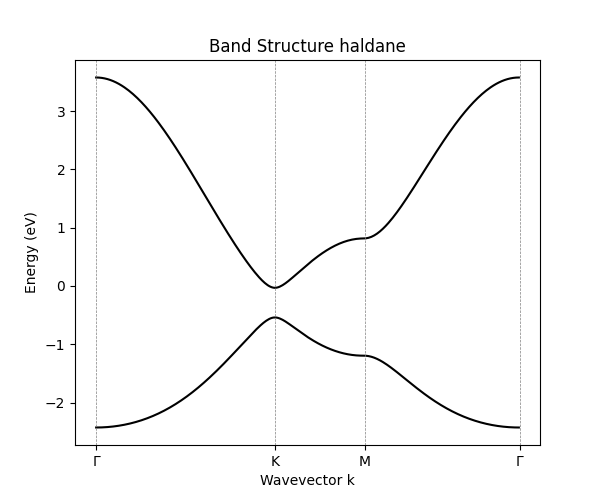

In [109]:
GetConfig("config_.yml")
GraphBands("Images/Tests")

band 0 C=(-2+2.9020151950916545e-16j))
band 1 C=(2.0000000000000004+1.5051622216202866e-16j))


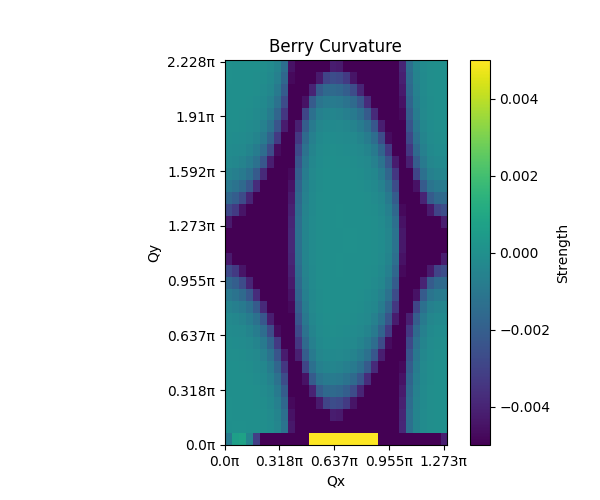

In [131]:
eps = sys_dict.get("epsilon")
ni_eval, ni_wf = SolveBzNoninteracting() #if I want to shift the k points to avoid zeros, send epsilon in this func.
BC, C = GetBerryCurvature1band(ni_wf[:,:,:,0])
GraphBerryCurvature(BC,C, "Images/Tests")
n_bands = sys_dict.get("Bands")
for n in range(n_bands):
    BC, C = GetBerryCurvature1band(ni_wf[:,:,:,n])
    print(f"band {n} C={C})")

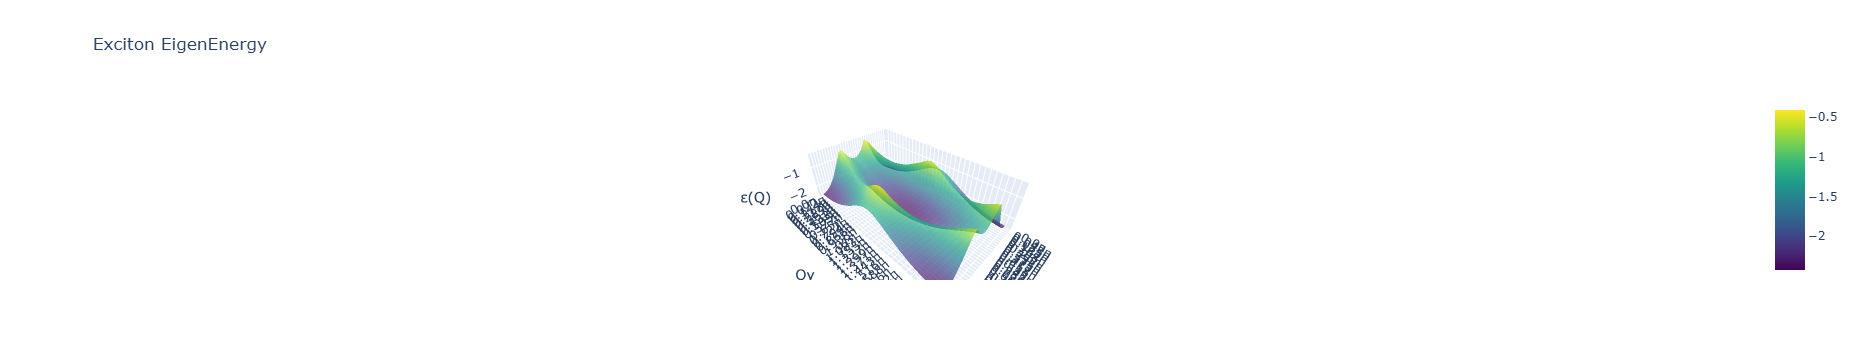

In [133]:
Graph3D(ni_eval,1,"Images/Tests")

In [151]:
print(np.shape(ni_wf))

(32, 32, 3, 3)


### Try to show how much the bands cross

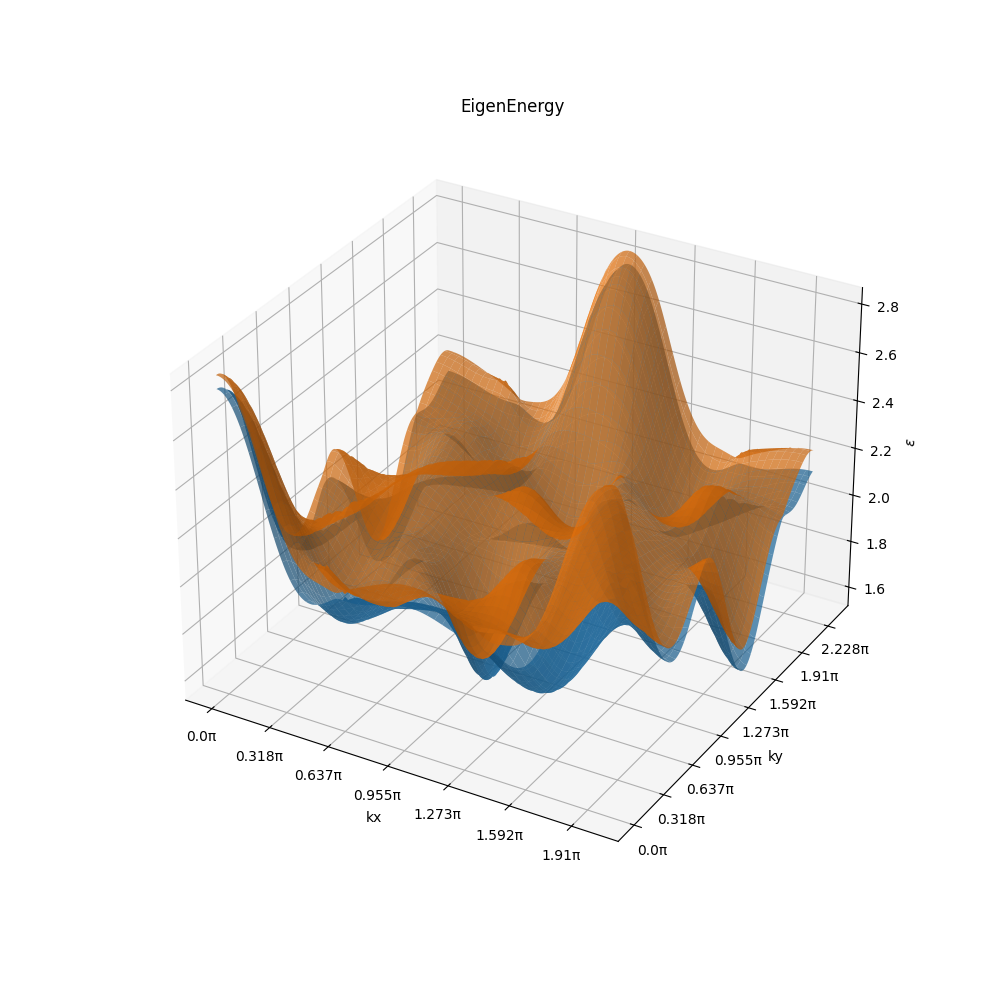

In [388]:
kx_list = sys_dict["kxlist"]
ky_list = sys_dict["kylist"]
kx_mesh, ky_mesh = np.meshgrid(kx_list,ky_list)
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
for i in range(2,4): #choose bands
    e_sheet = ni_eval[:,:,i]
    ax.plot_surface(kx_mesh, ky_mesh, e_sheet, alpha=0.7, label=f"band {i}")
ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))
ax.set_xlabel('kx')
ax.set_ylabel('ky')
ax.set_zlabel(r'$\epsilon$')
plt.title("EigenEnergy")
#output_path = os.path.join(output_folder, f'Energys3D n={n}.png')
#plt.savefig(output_path)
plt.show()

Number of near-degeneracies (band 3 ≈ band 2): 0


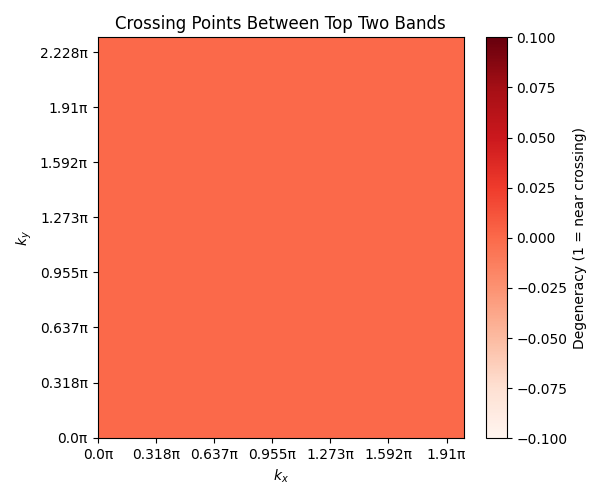

Crossing points (kx, ky):


In [412]:
# Load data
eig = ni_eval  # shape: (Nkx, Nky, 3)
kx_list = sys_dict["kxlist"]    # shape: (Nkx,)
ky_list = sys_dict["kylist"]    # shape: (Nky,)
# Threshold for near-degeneracy
epsilon = 1e-3

# Find near crossings between top two bands
delta = np.abs(eig[:, :, 3] - eig[:, :, 2])
crossing_mask = delta < epsilon
num_crossings = np.sum(crossing_mask)
print(f"Number of near-degeneracies (band 3 ≈ band 2): {num_crossings}")

# Build 2D coordinate grid
KX, KY = np.meshgrid(kx_list, ky_list, indexing='ij')  # shape: (Nkx, Nky)

# Your plotting code
plt.figure(figsize=(6, 5))
ax = plt.gca()  # get current axes

ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))

pcm = ax.pcolormesh(KX, KY, crossing_mask, cmap='Reds', shading='auto')
ax.set_title("Crossing Points Between Top Two Bands")
ax.set_xlabel(r"$k_x$")
ax.set_ylabel(r"$k_y$")
plt.colorbar(pcm, ax=ax, label='Degeneracy (1 = near crossing)')
plt.tight_layout()
plt.show()

# Get indices of True entries
ix, iy = np.where(crossing_mask)

# Map indices to actual kx, ky values
kx_crossings = KX[ix, iy]
ky_crossings = KY[ix, iy]
kx_pi = kx_crossings / np.pi
ky_pi = ky_crossings / np.pi
print("Crossing points (kx, ky):")
for kx_val, ky_val in zip(kx_pi, ky_pi):
    print(f"({kx_val}π, {ky_val}π)")

### Step 2
Define func get_H(Q,wf_array) which returns the 4D H tensor for each Q depending on the wavefunctions of the non interacting problem.
notes: currently assumes a 2 band system, therfore no consideration for difference between different bands c=c' v=v'.

#### WIP
in 2band $H_{cc'}^{vv'} == H_c^v$ currently calculates for v=v'=0 c=c'=1
in multiple bands we define ahead of time which bands are valence and which ar conduction and loop over those bands.
4 dimensions c,c',v,v': say vband =[0,1] cband=[2,3] are the indices of the valance and conduction bands then we have two options for each v,v' (either 0 or 1 each) and two options for c,c' (either 2,3 each). This means its H[(kx,ky),(kx_tag,ky_tag),c,c',v,v'], after that we need to squish this H to H_squish1[(kx,ky),(kx_tag,ky_tag),cc',vv'] -> H_squish2[[(kx,ky),(kx_tag,ky_tag),cc'vv']-> H_squish3[(kx,ky)(kx_tag,ky_tag),cc'vv']-> squish4 [(kx,ky)(kx',ky')cc'vv']-> squish5 [(kx,ky)kx'ky'cc'vv'] (where squish 5 is just like the first squish from 4d to 2d. basically we go from 8D to 2D in a manner that is bijective.

In [2]:
def GetH2Band(Qx_indx,Qy_indx,wf_ni, ni_evals):
    U = sys_dict["U"]
    epsilon = sys_dict["epsilon"]
    kxlist = sys_dict["kxlist"]
    kylist = sys_dict["kylist"]
    Nk = sys_dict["Nk"]
    interaction = sys_dict["interaction"]
    c_band = sys_dict["c_band"]
    v_band = sys_dict["v_band"]
    wk = 2/(np.sqrt(3)*pow(Nk,2)) #2/sqrt3 from triangular lattice
    H = np.zeros((Nk,Nk,Nk,Nk), dtype = complex)
    for kx in range(Nk):
        for ky in range(Nk):
            for kx_tag in range(Nk):
                for ky_tag in range(Nk):
                    kx_Qx = (kx+Qx_indx)%Nk  
                    kx_Qx_tag = (kx_tag+Qx_indx)%Nk
                    ky_Qy = (ky+Qy_indx)%Nk
                    ky_Qy_tag = (ky_tag+Qy_indx)%Nk
                    if kx==kx_tag and ky==ky_tag:
                        e = ni_evals[kx_Qx][ky_Qy][c_band]- ni_evals[kx][ky][v_band]
                    else:
                        e = 0
                    if interaction.get("kind") == "coulomb":
                        k_vec = np.array([kxlist[kx],kylist[ky]])
                        ktag_vec = np.array([kxlist[kx_tag],kylist[ky_tag]])
                        deltak_vec = k_vec-ktag_vec
                        deltak_norm  = np.linalg.norm(deltak_vec)
                        V_d = 1/(deltak_norm+epsilon)
                        if kx==kx_tag and ky==ky_tag:
                            V_d = 0
                        Q_vec = np.array([kxlist[Qx_indx],kylist[Qy_indx]])
                        Q_norm  = np.linalg.norm(Q_vec)
                        V_x = 1/(Q_norm+epsilon)
                    elif interaction.get("kind") == "constant":
                        params = interaction.get("params")
                        V_d = params.get('vd')
                        V_x = params.get('vx')
                    else:
                        raise ValueError("Could not parse acceptable interaction kind")
                    uc_kQ   = wf_ni[kx_Qx,ky_Qy,:,c_band]
                    uc_kpQ  = wf_ni[kx_Qx_tag,ky_Qy_tag,:,c_band]
                    uv_k    = wf_ni[kx,ky,:,v_band]
                    uv_kp   = wf_ni[kx_tag,ky_tag,:,v_band]
                    D = U*V_d*np.vdot(uc_kQ, uc_kpQ) * np.vdot(uv_kp, uv_k)
                    X = U*V_x*np.vdot(uc_kQ, uv_k) * np.vdot(uv_kp, uc_kpQ)
                    H[kx,ky,kx_tag,ky_tag] = e - wk*(D-X)
    return H

### Step 3
Loop over every Q from $-2\pi$ to $2\pi$ using the same difference between k's (so if k is 20x20 Q is 40x40). Flatten H to a 2D matrix. Solve the eigensystem of the 2D matrix, save the eigenvalues of Q.

In [1]:
def SolveInteracting(ni_evals,ni_wf):
    NQ = sys_dict["Nk"]
    Qxlist = sys_dict["kxlist"]
    Qylist = sys_dict["kylist"]
    dQx = np.abs(Qxlist[1] - Qxlist[0])
    dQy = np.abs(Qylist[1] - Qylist[0])
    Nk = sys_dict["Nk"]
    eQ_matrix = np.zeros((NQ,NQ,Nk*Nk))
    f_matrix = np.zeros((NQ,NQ,Nk*Nk,Nk*Nk),dtype=np.complex128)
    for i in range(NQ):#Qx
        for j in range(NQ):#Qy
            H_Q = GetH2Band(i,j,ni_wf,ni_evals)
            H_Q2D = Flatten4D(H_Q)
            e_Q, f_Q = np.linalg.eigh(H_Q2D)
            # Sort the eigenvalues and reorder eigenvectors accordingly
            sorted_indices = np.argsort(e_Q)
            sorted_e_Q = e_Q[sorted_indices]
            sorted_f_Q = f_Q[:, sorted_indices]
            sorted_e_Q = np.real(sorted_e_Q)
            eQ_matrix[i,j]= sorted_e_Q
            f_matrix[i,j] = sorted_f_Q
    return(eQ_matrix,f_matrix)

note about flattening, we go from $H_{ijkl} -> H_{i'j'}$, I want the first index to represent k and the second to represent k'. in order to do that I flattened it in such a way that $i' = i*N_{ky} + j$ and $j' = k*N_{ky} +l$ I feel like this makes the most sense. To unwind simply take floor or modulu of the index by N.

In [79]:
def Flatten4D(array4D):
    Nk = sys_dict["Nk"]
    imax,jmax,kmax,lmax = Nk,Nk,Nk,Nk #this can be made more generic but im trying to minmax efficiency a little bit
    # Flatten the 4D array to a 2D array using explicit index mapping
    array2D = np.empty((imax * jmax, kmax * lmax), dtype=complex)
    for i in range(imax):
        for j in range(jmax):
            for k in range(kmax):
                for l in range(lmax):
                    # Map 4D indices to 2D indices
                    row = i * jmax + j
                    col = k * lmax + l
                    array2D[row, col] = array4D[i, j, k, l]
    return array2D

# Verify index mapping
#for i in range(imax):
#    for j in range(jmax):
#        for k in range(kmax):
#            for l in range(lmax):
#                if array2D[i * jmax + j][k * lmax + l] != array4D[i][j][k][l]:
#                    print("Error in mapping")

In [117]:
#unused, Unflatten
def UnFlatten2D(array2D):
    # Reverse the flattening process
    for row in range(imax * jmax):
        for col in range(kmax * lmax):
            # Convert 2D indices (row, col) back to 4D indices (i, j, k, l)
            i = row // jmax
            j = row % jmax
            k = col // lmax
            l = col % lmax
            
            # Assign the value from 2D array to 4D array
            array4D[i, j, k, l] = array2D[row, col]
    return array4D

### Step 4
Exciton wave functions:
$u_{exc}(Q) = /Sum_{k_x,k_y}F(k,Q)u^c$

### Step 5
graphs

In [113]:
def Graph3D(eQ_matrix,n,output_folder):
    #eQ_matrix is the completed exciton eigenenergies grid while n is the number of energy levels we wish to show
    Qxlist = sys_dict["kxlist"]
    Qylist = sys_dict["kylist"]
    Qx_mesh, Qy_mesh = np.meshgrid(Qxlist,Qylist)
    #sys_dict["Qxlist"] = np.linspace(0,4*np.pi,2*Nk-1)
    #sys_dict["Qylist"] = np.linspace(0,8*np.pi/np.sqrt(3),2*Nk-1)
    fig = go.Figure()
    for i in range(n): #choose bands
        eQ_sheet = eQ_matrix[:,:,i]
        fig.add_surface(
            x=Qx_mesh, y=Qy_mesh, z=eQ_sheet,
            opacity=0.7,
            name=f"band {i}",
            colorscale="Viridis"
        )

    tick_labels_x = PiFormatter_plotly(Qxlist)
    tick_labels_y = PiFormatter_plotly(Qylist)
    fig.update_layout(
        scene=dict(
            xaxis=dict(
                title="Qx",
                tickvals=Qxlist,
                ticktext=tick_labels_x
            ),
            yaxis=dict(
                title="Qy",
                tickvals=Qylist,
                ticktext=tick_labels_y
            ),
            zaxis=dict(title="ε(Q)")
        ),
        title="Exciton EigenEnergy"
    )

    output_path = os.path.join(output_folder, f"Energys3D_n={n}.html")
    fig.write_html(output_path)
    return fig

In [114]:
#Only for chern insulator rn
def GraphQxConst(eQ_matrix,output_folder):
    fig, ax = plt.subplots(figsize=(6, 6))
    #Qxlist= sys_dict["Qxlist"]
    Qylist = sys_dict["kylist"]
    Nk= sys_dict["Nk"]
    epsilon = sys_dict["epsilon"]
    U= sys_dict["U"]
    #M = sys_dict["M"]
    rows, cols, n = eQ_matrix.shape
    center_row = rows // 2
    center_plus1 = rows - center_row
    #band = np.zeros(3*(center_plus1))
    count = n
    for i in range(count):
       # line1 = [eQ_matrix[center_row + j-1, center_row + j-1,i] for j in range(center_plus1)]
       # line2 = [eQ_matrix[rows-1, rows - j-2,i] for j in range(center_plus1-1)] #-2 and -1 to avoid using the same point twice
       # line3 = [eQ_matrix[rows - j-1, center_row-1,i] for j in range(center_plus1-1)]
       # band = line1 + line2 + line3
        band = [eQ_matrix[center_row,j,i] for j in range(cols)]
        ax.plot(Qylist,band)

    #xticks_positions = [
    #    0,                      # Start of the first line
    #    len(line1)-1,         # End of the first line
    #    len(line1) + len(line2)-2,  # End of the second line
    #    len(band)-1          # End of the third line
    #]
    #xtick_labels = [r"$\Gamma$", r"M", r"X", r"$\Gamma$"]
    # Set custom xticks
    #plt.xticks(ticks=xticks_positions, labels=xtick_labels)
    ax.set_xlabel("Qy")
    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.set_ylabel("energy") #good dealer
    #plt.legend()
    #output_path = os.path.join(output_folder, f'Nk={Nk},epsilon={epsilon},U={U},M={M}.png')
    output_path = os.path.join(output_folder, f'Energys Qx=center.png')
    fig.savefig(output_path)
#GraphQxConst(eQ_matrix)

In [115]:
def GraphIntegratedF(F,output_folder):
    x = sys_dict["kxlist"]
    y = sys_dict["kylist"]
    fig, ax = plt.subplots(figsize=(6, 6))
    
    im = ax.imshow(F, aspect='equal', origin='lower',
               extent=[x[0], x[-1], y[0], y[-1]])
    
    # Apply formatter to x-axis
    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))
    cbar = fig.colorbar(im,ax=ax,label='F value abs')
    ax.set_xlabel('Qx')
    ax.set_ylabel('Qy')
    ax.set_title('Integrated F (abs)')
    #output_path = os.path.join(output_folder, f'Nk={Nk},epsilon={epsilon},U={U},M={M}.png')
    output_path = os.path.join(output_folder, f'Integrated F[0].png')
    fig.savefig(output_path)

In [116]:
from matplotlib.colors import Normalize
def GraphFPhase(F,output_folder):
    x = sys_dict["kxlist"]
    y = sys_dict["kylist"]
    fig = plt.figure()
    im = plt.imshow(F, aspect='equal', origin='lower',
               extent=[x[0], x[-1], y[0], y[-1]])
    
    # Apply formatter to x-axis
    ax = plt.gca()
    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))
    cb = plt.colorbar(im, label='Phase')
    ticks = cb.get_ticks()
    cb.set_ticklabels([PiFormatter(t, None) for t in ticks])
    ax.set_xlabel('Qx')
    ax.set_ylabel('Qy')
    ax.set_title('Integrated F phase')
    #output_path = os.path.join(output_folder, f'Nk={Nk},epsilon={epsilon},U={U},M={M}.png')
    output_path = os.path.join(output_folder, f'F[0] Phase.png')
    fig.savefig(output_path)

In [117]:
def GraphFPhaseQuiver(F,output_folder):
    x = sys_dict["kxlist"]
    y = sys_dict["kylist"]
    X, Y = np.meshgrid(x, y, indexing='ij')

    # Convert phase to unit vector components
    U = np.cos(F)
    V = np.sin(F)

    # Flatten for quiver, which expects 1D arrays for coloring
    X_flat = X.ravel()
    Y_flat = Y.ravel()
    U_flat = U.ravel()
    V_flat = V.ravel()

    fig = plt.figure(figsize=(6, 6))
    q = plt.quiver(X_flat, Y_flat, U_flat, V_flat,
                   color='black', pivot='middle', scale=55)

    ax = plt.gca()
    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))

    # Add a colorbar showing the phase values
    cbar = plt.colorbar(q, label='Phase (radians)')
    ticks = cbar.get_ticks()
    cbar.set_ticklabels([PiFormatter(t, None) for t in ticks])

    ax.set_xlabel('Qx')
    ax.set_ylabel('Qy')
    ax.set_title('Integrated F phase (quiver)')

    os.makedirs(output_folder, exist_ok=True)
    output_path = os.path.join(output_folder, 'F[0] Phase (quiver).png')
    fig.savefig(output_path)

In [118]:
def periodic_gradient(f,dQx,dQy):
    fx_forward = np.roll(f, -1, axis=0)
    fx_backward = np.roll(f, 1, axis=0)
    fy_forward = np.roll(f, -1, axis=1)
    fy_backward = np.roll(f, 1, axis=1)
    
    dfdx = (fx_forward - fx_backward) / (2*dQx)
    dfdy = (fy_forward - fy_backward) / (2*dQy)
    
    return dfdx, dfdy
def periodic_vorticity(u, v, dQx, dQy):
    #dv/dx
    dv_forward = np.roll(v, -1, axis=0)
    dv_backward = np.roll(v, 1, axis=0)
    dvdx = (dv_forward - dv_backward) / (2*dQx)
    
    # du/dy
    du_forward = np.roll(u, -1, axis=1)
    du_backward = np.roll(u, 1, axis=1)
    dudy = (du_forward - du_backward) / (2*dQy)
    
    return dvdx - dudy
def GraphFVorticity(F,output_folder): #takes F field
    logF = np.log(F)
    Qxlist = sys_dict["kxlist"]
    Qylist = sys_dict["kylist"]
    dQx = np.abs(Qxlist[1] - Qxlist[0])
    dQy = np.abs(Qylist[1] - Qylist[0])
    u,v = periodic_gradient(logF,dQx,dQy) #dlogF
    vor = periodic_vorticity(np.real(1j*u),np.real(1j*v),dQx,dQy) #∇Xi(dlog(F))
    fig = plt.figure()
    im = plt.imshow(vor, aspect='equal', origin='lower',
               extent=[Qxlist[0], Qxlist[-1], Qylist[0], Qylist[-1]])
    
    # Apply formatter to x-axis
    ax = plt.gca()
    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))
    cb = plt.colorbar(im, label='Vorticity')
    #ticks = cb.get_ticks()
    #cb.set_ticklabels([PiFormatter(t, None) for t in ticks])
    ax.set_xlabel('Qx')
    ax.set_ylabel('Qy')
    ax.set_title('Integrated F singular connection vorticity')
    #output_path = os.path.join(output_folder, f'Nk={Nk},epsilon={epsilon},U={U},M={M}.png')
    output_path = os.path.join(output_folder, f'Singular connection[0] vorticity.png')
    fig.savefig(output_path)

# Processing after solving BS

## load data

In [136]:
folder_name = "2025-11-17_11-02-34"
load_folder = f"Data/{folder_name}"
configfile = os.path.join(load_folder, "config.yml")
GetConfig(configfile)
F0file = os.path.join(load_folder, "F[0].npy")
F0 = np.load(F0file, mmap_mode='r')
integratedFfile = os.path.join(load_folder, "Integrated_Fs.npy")
integrated_f = np.load(integratedFfile, mmap_mode='r')
eQfile = os.path.join(load_folder, "Exciton_Energys.npy")
eQ = np.load(eQfile, mmap_mode='r')

## Extract and graph information

C:\Users\theof\AppData\Local\Temp\ipykernel_15624\3869166844.py:27: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



(5.963540027744095e-17-7.685365354735166e-16j)


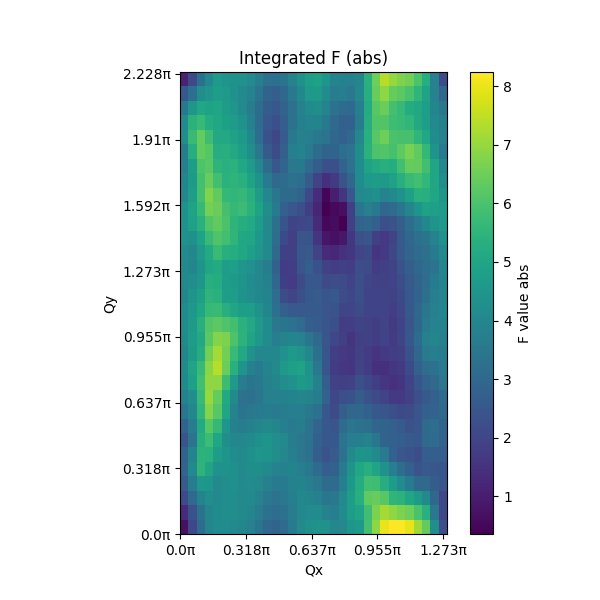

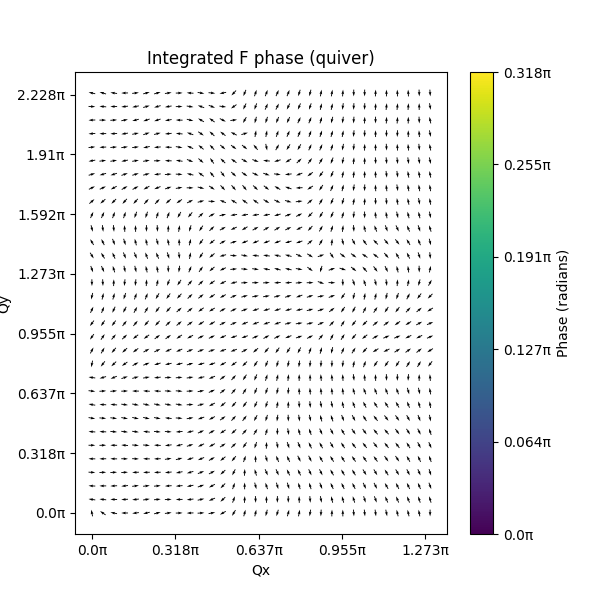

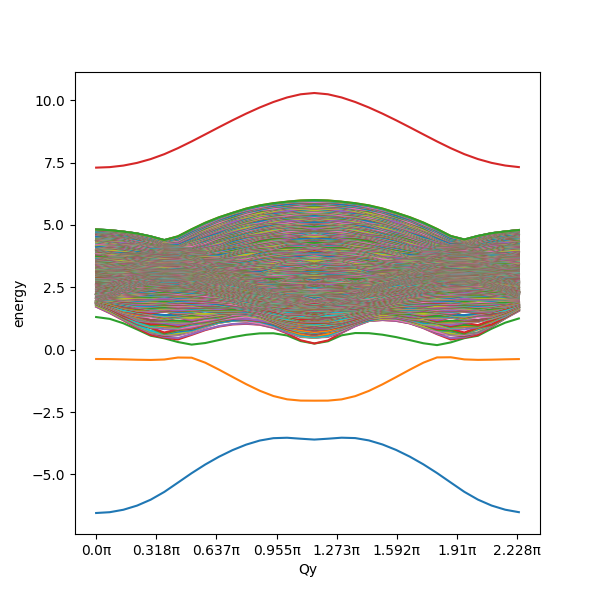

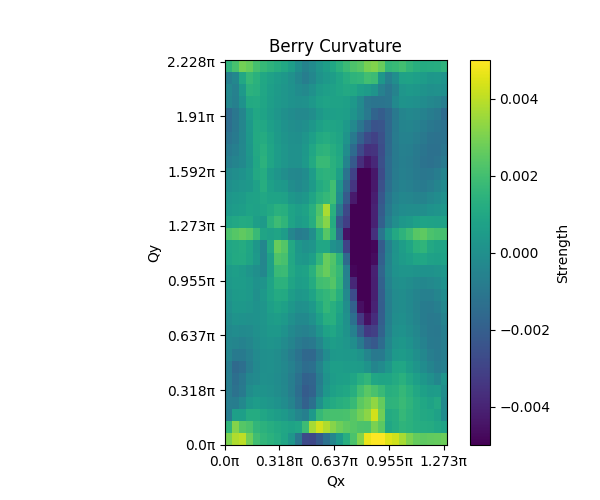

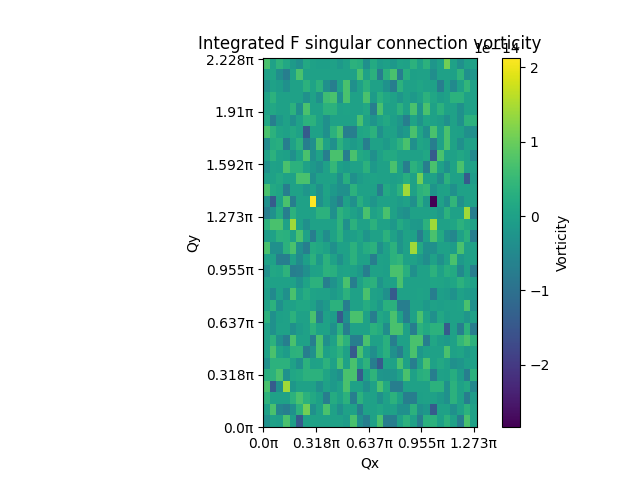

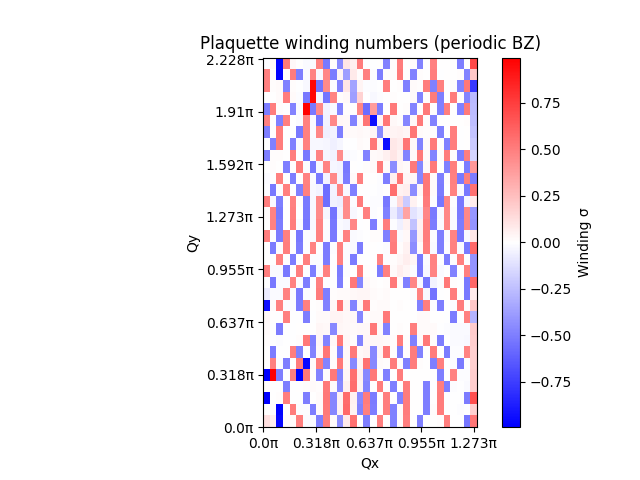

In [137]:
abs_integrated_f_matrix = np.abs(integrated_f[:,:,0])
phase_integrated_f_matrix = np.angle(integrated_f[:,:,0])
GraphIntegratedF(abs_integrated_f_matrix,load_folder)
GraphFPhaseQuiver(phase_integrated_f_matrix,load_folder)
GraphQxConst(eQ,load_folder)
Graph3D(eQ,1,load_folder)
BC,C = GetBerryCurvature1band(F0)
GraphBerryCurvature(BC,C,load_folder)
print(C)
GraphFVorticity(integrated_f[:,:,0],load_folder)
plaquette_winding_map_periodic(integrated_f[:,:,0],load_folder)

# misc

In [78]:
def add_title_to_image(image_path, title, font_size=40, padding=10):
    image = Image.open(image_path)
    width, height = image.size

    # Height for the title space, which includes padding
    title_height = font_size + 2 * padding

    # Create a new image with extra space for the title (white background)
    new_image = Image.new("RGB", (width, height + title_height), "white")

    # Paste the original image below the title space
    new_image.paste(image, (0, title_height))  # (0, title_height) places the image below the title area

    # Draw the title
    draw = ImageDraw.Draw(new_image)

    try:
        # Attempt to load a font, otherwise fallback to default
        font = ImageFont.truetype("arial.ttf", font_size)
    except IOError:
        font = ImageFont.load_default()  # Fallback to default if Arial is missing

    # Use textbbox() to get text size
    bbox = draw.textbbox((0, 0), title, font=font)
    text_width = bbox[2] - bbox[0]
    text_height = bbox[3] - bbox[1]

    # Center the text within the title space
    text_x = (width - text_width) // 2  # Horizontally center
    text_y = (title_height - text_height) // 2  # Vertically center with padding

    # Draw the title in black for visibility
    draw.text((text_x, text_y), title, fill="black", font=font)

    return new_image

In [146]:
def MakeGifs(rs):
    # Define input and output folders
    image_folder = Path("Images")/source_path
    output_folder = Path("Gifs")/source_path
    os.makedirs(output_folder, exist_ok=True)  # Ensure output folder exists
    
    # Here write an array for whatever variable
    #Nk_range =  list(range(8,16,2))
    #U_range = list(range(8, 25, 4))
    #epsilon_range = [1e-2,1e-3,1e-4,1e-5]
    # Define constants
    #_N = "14"
    #_epsilon = "1e-05"
    #_U = "16" 
    #_M = "-1.1"
    matching_images=[]
    for r in rs:
        file_path = image_folder / f"r={r}.png"
        if file_path.exists():
            matching_images.append(file_path)
        else:
            print("File not found:", file_path)
    
    processed_images = []
    for img_path in matching_images:
        fname = img_path.name
        if re.search(r"r=inf", fname, flags=re.IGNORECASE):
            title = "r = ∞"
            print("Extracted ratio: r = ∞")

        else:
            # 1) Try to match r=[x]%[y]
            match = re.search(r"r=([+-]?\d*\.?\d+)%([+-]?\d*\.?\d+)", fname, flags=re.IGNORECASE)
            if match:
                x, y = match.group(1), match.group(2)
                title = f"r= {x}/{y}"
                print("Extracted ratio:", title)
            else:
                # 2) Fallback to your original U=... handling
                match = re.search(r"r=([+-]?\d*\.?\d+)", fname, flags=re.IGNORECASE)
                if match:
                    _value = float(match.group(1))
                    print("Extracted value:", _value)
                    title = f"r = {np.round(_value,1)}"
                else:
                    print("No r=...%... or r=... found in filename")
                    title = fname  # last-resort fallback

        new_img = add_title_to_image(img_path, title)
        processed_images.append(new_img)
    
    if len(processed_images)>0:
        # Open the first image as the base
        #frames = [Image.open(img) for img in processed_images]
        
        # Save as GIF (loop=0 makes it loop indefinitely)
        output_gif_path = os.path.join(output_folder, f"ratio xd mod coulomb.gif")
        #frames[0].save(output_gif_path, save_all=True, append_images=frames[1:], duration=500, loop=0)
        processed_images[0].save(output_gif_path, save_all=True, append_images=processed_images[1:], duration=500, loop=0)
        print("GIF saved as:", output_gif_path)
    else:
        print("No matching images found, GIF not created.")

In [148]:
source_path= Path("Explorations/ratio exploration/full/Berry Curvature")
rs = ["0","1%32","1%16","1%8","1%4","1%2","1","2","4","8","16","32","inf"]
MakeGifs(rs)

Extracted value: 0.0
Extracted ratio: r= 1/32
Extracted ratio: r= 1/16
Extracted ratio: r= 1/8
Extracted ratio: r= 1/4
Extracted ratio: r= 1/2
Extracted value: 1.0
Extracted value: 2.0
Extracted value: 4.0
Extracted value: 8.0
Extracted value: 16.0
Extracted value: 32.0
Extracted ratio: r = ∞
GIF saved as: Gifs\Explorations\ratio exploration\full\Berry Curvature\ratio xd mod coulomb.gif


In [134]:
def combine_gifs_side_by_side(gif1_path, gif2_path, output_path):
    gif1 = Image.open(gif1_path)
    gif2 = Image.open(gif2_path)

    # Convert all frames to RGB to avoid palette issues
    frames1 = [frame.convert("RGB") for frame in ImageSequence.Iterator(gif1)]
    frames2 = [frame.convert("RGB") for frame in ImageSequence.Iterator(gif2)]

    if len(frames1) != len(frames2):
        raise ValueError("GIFs must have the same number of frames")

    combined_frames = []

    for f1, f2 in zip(frames1, frames2):
        # Resize to match height
        if f1.height != f2.height:
            new_height = min(f1.height, f2.height)
            f1 = f1.resize(
                (int(f1.width * new_height / f1.height), new_height),
                Image.Resampling.LANCZOS
            )
            f2 = f2.resize(
                (int(f2.width * new_height / f2.height), new_height),
                Image.Resampling.LANCZOS
            )

        # Combine side by side
        combined_width = f1.width + f2.width
        combined = Image.new("RGB", (combined_width, f1.height))
        combined.paste(f1, (0, 0))
        combined.paste(f2, (f1.width, 0))
        combined_frames.append(combined)

    # Save as palette-based GIF ("P" mode)
    combined_frames = [frame.convert("P", palette=Image.ADAPTIVE) for frame in combined_frames]

    combined_frames[0].save(
        output_path,
        save_all=True,
        append_images=combined_frames[1:],
        duration=gif1.info.get("duration", 100),
        loop=0,
        disposal=2
    )

# Example usage
combine_gifs_side_by_side(
    Path("Gifs/HW/Changing M - Bands.gif"),
    Path("Gifs/HW/Changing M - BC.gif"),
    Path("Gifs/HW/Changing M.gif")
)


## tests

In [121]:
def plaquette_winding_map_periodic(F, output_folder):
    """
    Compute integer winding numbers of F(Q) phase around each plaquette,
    taking into account periodic boundary conditions in both directions.
    Returns a (ny, nx) array of integers (one per plaquette).
    """
    Qxlist = sys_dict["kxlist"]
    Qylist = sys_dict["kylist"]
    ny, nx = F.shape
    windings = np.zeros((ny, nx))

    for iy in range(ny):
        for ix in range(nx):
            # periodic indices
            ixp = (ix + 1) % nx
            iyp = (iy + 1) % ny

            loop = [F[iy, ix], F[iy, ixp], F[iyp, ixp], F[iyp, ix]]
            phases = np.angle(loop)
            #dphi = np.diff(np.unwrap(phases))
            dphi = np.diff(phases)
            winding = (np.sum(dphi) / (2*np.pi))
            windings[iy, ix] = winding

    # Plot
    fig, ax = plt.subplots()
    extent = [Qxlist[0], Qxlist[-1], Qylist[0], Qylist[-1]]
    im = ax.imshow(windings.T, origin="lower", extent=extent,
                   aspect="equal", cmap="bwr",)

    ax.xaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.yaxis.set_major_formatter(FuncFormatter(PiFormatter))
    ax.set_xlabel("Qx")
    ax.set_ylabel("Qy")
    ax.set_title("Plaquette winding numbers (periodic BZ)")
    cb = plt.colorbar(im, ax=ax, label="Winding σ")

    output_path = os.path.join(output_folder, f"Plaquette_windings_periodic {np.sum(windings)}.png")
    fig.savefig(output_path)

    #return windings

#windings = plaquette_winding_map_periodic(integrated_f[:,:,0],Qxlist,Qylist,load_folder)
#print(np.sum(windings))

In [69]:
Nk = F0.shape[0]
F0_fixed= np.zeros_like(F0)
F0_fixed[0,0,:] = F0[0,0,:]

# propagate along ky (j direction)
for j in range(1, Nk):
    prev = F0_fixed[0, j-1, :]
    cur  = F0[0, j, :]
    ov = np.vdot(prev, cur)
    if np.abs(ov) > 1e-12:
        phase = ov/np.abs(ov)
    else:
        phase = 1.0
    F0_fixed[0, j, :] = cur * phase.conjugate()
# now propagate in kx (i direction)
for i in range(1, Nk):
    # first element in row
    prev = F0_fixed[i-1, 0, :]
    cur  = F0[i, 0, :]
    ov = np.vdot(prev, cur)
    if np.abs(ov) > 1e-12:
        phase = ov/np.abs(ov)
    else:
        phase = 1.0
    F0_fixed[i, 0, :] = cur * phase.conjugate()
    # then along ky in this row
    for j in range(1, Nk):
        prev = F0_fixed[i, j-1, :]
        cur  = F0[i, j, :]
        ov = np.vdot(prev, cur)
        if np.abs(ov) > 1e-12:
            phase = ov/np.abs(ov)
        else:
            phase = 1.0
        F0_fixed[i, j, :] = cur * phase.conjugate()

In [149]:
print(np.shape(F0))

(32, 32, 1024)
